# Finding files by type and suffix

Compare matching file counts across two branches of a temporary directory tree.

find applies each predicate to each entry. Grouping by a directory is easy here because each argument names a separate subtree. A quoted pattern is passed to find for matching.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
mkdir -p a/nested b
touch a/one.csv a/two.txt a/nested/three.csv b/one.csv b/photo.png
for directory in a b; do
    find "$directory" -type f -name '*.csv' -exec sh -c 'for f do printf "1\n"; done' sh {} + | wc -l
done
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [2, 1]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [2, 1]
bash [2, 1]
zsh [2, 1]


## Inspect the outcome

The records counted by wc contain a constant marker. A newline in a matched filename cannot create a spurious count.

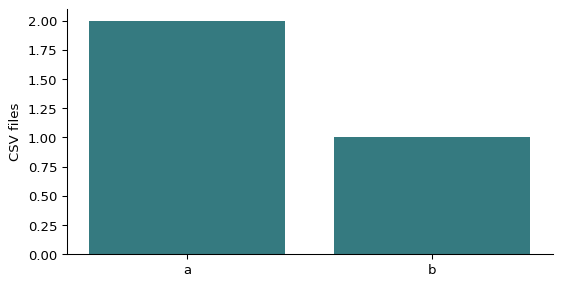

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["a", "b"], observed, color="#357a80")
ax.set(ylabel="CSV files")
plt.show()

## Interpreting the result

The records counted by wc contain a constant marker. A newline in a matched filename cannot create a spurious count.

## Exercise

Put a CSV file one level deeper and compare recursive and top-level counts.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)